# Can timing and stake repetition help describe an account?

I build features for accounts with at least 100 wagers in a game. Working within each game helps keep differences in game pace from driving the comparison. These features describe the full observed period and are intended for exploration.

In [1]:
%matplotlib inline
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect("../private/wagers.duckdb", read_only=True,
                     config={"threads": 4, "memory_limit": "3GB",
                             "temp_directory": "../private/eda-spill"})

In [2]:
features = con.sql('''
    WITH ordered AS (
        SELECT member, game, bet, date, min_time_stamp,
               epoch(min_time_stamp) - epoch(lag(min_time_stamp) OVER account_game) AS gap,
               lag(bet) OVER account_game AS previous_stake
        FROM wagers
        WHERE member IS NOT NULL AND min_time_stamp IS NOT NULL AND bet > 0
        WINDOW account_game AS (
            PARTITION BY member, game ORDER BY min_time_stamp, tableNO, shoe_ref, shoe_hand, bet
        )
    )
    SELECT game, count(*) AS hands, count(DISTINCT date) AS active_days,
           median(gap) FILTER (WHERE gap > 0 AND gap <= 1800) AS median_gap,
           stddev_pop(gap) FILTER (WHERE gap > 0 AND gap <= 1800)
               / nullif(avg(gap) FILTER (WHERE gap > 0 AND gap <= 1800), 0) AS gap_cv,
           avg((bet = previous_stake)::INT) FILTER (WHERE gap > 0 AND gap <= 1800) AS repeat_stake,
           stddev_pop(bet) / avg(bet) AS stake_cv
    FROM ordered GROUP BY member, game HAVING count(*) >= 100
''').df()

A gap is the time between consecutive wagers by the same account in the same game. I leave tied timestamps and gaps over 30 minutes out of the within-session calculations. The coefficient of variation (CV) divides standard deviation by the mean. A low gap CV means the included gaps are relatively consistent, while a low stake CV means wager amounts vary little relative to their typical size. Repeat stake is the share of included transitions with exactly the same amount.

,hands,active_days,median_gap,gap_cv,repeat_stake,stake_cv
game,,,,,,
dragon_tiger,328.0,13.0,30.13,2.13,0.33,0.86
non_com,516.0,18.0,45.08,1.76,0.39,0.79
traditional,333.0,11.0,44.09,1.64,0.31,0.82


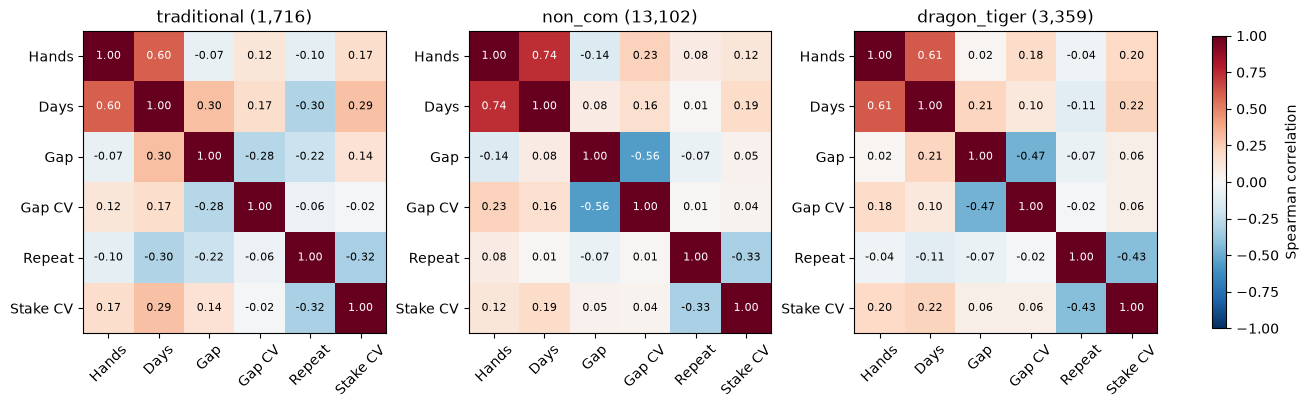

In [3]:
games = ["traditional", "non_com", "dragon_tiger"]
columns = ["hands", "active_days", "median_gap", "gap_cv", "repeat_stake", "stake_cv"]
selected = features[features["game"].isin(games)]
display(selected.groupby("game")[columns].median().round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), layout="constrained")
labels = ["Hands", "Days", "Gap", "Gap CV", "Repeat", "Stake CV"]
for ax, game in zip(axes, games):
    subset = selected.loc[selected["game"] == game, columns]
    correlations = subset.corr(method="spearman", min_periods=30)
    image = ax.imshow(correlations, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set(title=f"{game} ({len(subset):,})", xticks=range(len(labels)),
           yticks=range(len(labels)), xticklabels=labels, yticklabels=labels)
    ax.tick_params(axis="x", labelrotation=45)
    for i in range(len(labels)):
        for j in range(len(labels)):
            value = correlations.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                    color="white" if abs(value) > 0.55 else "black", fontsize=8)
fig.colorbar(image, ax=axes, shrink=0.7, label="Spearman correlation")
plt.show()
con.close()

Spearman correlation compares ranks, so a few extremely large values do not dominate it. Hands and active days measure related aspects of activity. Repeat stake and stake CV both describe stake consistency, but one measures successive wagers and the other measures overall dispersion. The heatmaps show how those relationships vary by game. None of these measurements identifies who is coordinating with whom. That is the question for the shared-round audit.

The median of account-level median gaps was about 30 seconds in Dragon/Tiger and 44–45 seconds in the two baccarat variants shown. The median exact-stake repeat share ranged from 31% to 39%. A single pace or repetition threshold across games would compare accounts against different baselines.